In [1]:
import os
import uuid
import hashlib
import platform
import numpy
import scipy
import matplotlib
import pandas
numpy.set_printoptions(threshold=numpy.inf)  # 显示所有元素

STUDENT_ID = 20244320114

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] pyexp
[学号] 20244320114
[机器指纹] 2a9f8f4b934fcb62
[RUN_ID] 20244320114-2a9f8f4b934fcb62


实验1：numpy数组、数据类型与索引

In [2]:
numpy.set_printoptions(threshold=numpy.inf)  # 显示所有元素
# 1. 创建整数、浮点数、布尔ndarray，输出dtype,shape,ndim
int_arr = numpy.array([1,2,3,4])
float_arr = numpy.array([1.1,2.2,3.3])
bool_arr = numpy.array([True, False, True])

print("整数数组")
print(f"array:{int_arr}, dtype:{int_arr.dtype}, shape:{int_arr.shape}, ndim:{int_arr.ndim}")
print("浮点数数组")
print(f"array:{float_arr}, dtype:{float_arr.dtype}, shape:{float_arr.shape}, ndim:{float_arr.ndim}")
print("布尔数组")
print(f"array:{bool_arr}, dtype:{bool_arr.dtype}, shape:{bool_arr.shape}, ndim:{bool_arr.ndim}")

# 2. arange(12)修改形状
a1 = numpy.arange(12)
a2 = a1.reshape(3,4)
a3 = a1.reshape(2,3,2)
print("\nreshape(3,4)")
print(a2)
print("\nreshape(2,3,2)")
print(a3)


整数数组
array:[1 2 3 4], dtype:int64, shape:(4,), ndim:1
浮点数数组
array:[1.1 2.2 3.3], dtype:float64, shape:(3,), ndim:1
布尔数组
array:[ True False  True], dtype:bool, shape:(3,), ndim:1

reshape(3,4)
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2)
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [3]:
#3 (3,4)数组索引
print("\n索引操作 形状(3,4)数组")
row2 = a2[1,:] #取第2行，下标从0开始
col1_3 = a2[:,0:3] #取1~3列
gt6 = a2[a2>6]#取大于6的元素
print("第2行：",row2, "shape:",row2.shape)
print("\n")
print("1至3列：",col1_3, "shape:",col1_3.shape)
print("\n")
print("大于6元素：",gt6, "shape:",gt6.shape)


索引操作 形状(3,4)数组
第2行： [4 5 6 7] shape: (4,)


1至3列： [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)


大于6元素： [ 7  8  9 10 11] shape: (5,)


In [4]:
#4 布尔条件筛选
arr10 = numpy.arange(10)
sel1 = arr10[(arr10 <2) | (arr10>7)]
sel2 = arr10[(arr10>3) & (arr10<7)]
sel12 = arr10[numpy.logical_or(arr10 < 2,arr10 >7)]
sel22 = arr10[numpy.logical_and(arr10 > 3,arr10 <7)]
print("\n布尔筛选")
print("\n小于2或大于7：",sel1)
print("\n小于2或大于7logical：",sel12)
print("\n大于3且小于7：",sel2)
print("\n大于3且小于7logical：",sel22)



布尔筛选

小于2或大于7： [0 1 8 9]

小于2或大于7logical： [0 1 8 9]

大于3且小于7： [4 5 6]

大于3且小于7logical： [4 5 6]


In [5]:
#5 * multiply() @ matmul() 逐元素乘法vs矩阵乘法
m1 = numpy.array([[1,2],[3,4]])
m2 = numpy.array([[5,6],[7,8]])
print("\n逐元素乘法与矩阵乘法")
print("m1 * m2：\n", m1*m2)
print("np.multiply(m1,m2):\n", numpy.multiply(m1,m2))
print("@矩阵乘法：\n", m1 @ m2)
print("np.matmul(m1,m2):\n", numpy.matmul(m1,m2))


逐元素乘法与矩阵乘法
m1 * m2：
 [[ 5 12]
 [21 32]]
np.multiply(m1,m2):
 [[ 5 12]
 [21 32]]
@矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul(m1,m2):
 [[19 22]
 [43 50]]


NumPy数组vs Python列表：
1. numpy数组所有元素必须是同一个数据类型；列表可以存放不同类型对象
2. ndarray 有 shape、ndim 维度属性，支持批量向量化运算；列表需要循环遍历
reshape 改变形状条件：新 shape 所有维度乘积 = 数组总元素个数
`*` /multiply：逐元素相乘；`@`/matmul：数学矩阵乘法。

实验2：随机抽样、统计、缺失值

In [6]:
numpy.random.seed(42) #固定随机种子！

#1 生成1000个成绩，均值70，标准差10，clip限制0‑100
scores = numpy.random.normal(loc=70, scale=10, size=1000)
scores = numpy.clip(scores,0,100)
print("模拟成绩统计")
print(f"样本数:{len(scores)}")
print(f"min:{scores.min():.2f}, max:{scores.max():.2f}")
print(f"均值:{scores.mean():.2f},标准差:{scores.std():.2f}")
print(f"极差:{scores.max()-scores.min():.2f}")

#2 不放回抽样；均匀抽样、加权抽样
pop = numpy.arange(1,11)
sample_uniform = numpy.random.choice(pop, size=5, replace=False)
sample_weight = numpy.random.choice(pop,size=5,replace=False, p=pop/numpy.sum(pop))
print("\n抽样")
print("均匀不放回抽样：", sample_uniform)
print("按数值大小加权抽样：", sample_weight)


模拟成绩统计
样本数:1000
min:37.59, max:100.00
均值:70.18,标准差:9.76
极差:62.41

抽样
均匀不放回抽样： [ 4  9  2  6 10]
按数值大小加权抽样： [10  2  8  9  6]


In [7]:
#3 random.permutation返回新数组；shuffle原地打乱
arr_ori = numpy.array([1,2,3,4,5])
arr_copy = arr_ori.copy()
permuted = numpy.random.permutation(arr_copy)
print("\npermutation(随机排列后保留原数组)")
print("原数组：", arr_copy)
print("返回新打乱数组：", permuted)

arr_shuf = numpy.array([1,2,3,4,5])
print("\nshuffle原地打乱")
print("shuffle前：", arr_shuf)
numpy.random.shuffle(arr_shuf)
print("shuffle后原数组改变：", arr_shuf)


permutation(随机排列后保留原数组)
原数组： [1 2 3 4 5]
返回新打乱数组： [5 1 3 2 4]

shuffle原地打乱
shuffle前： [1 2 3 4 5]
shuffle后原数组改变： [1 5 2 4 3]


In [8]:
#4 设置nan缺失值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = numpy.nan #第10、20、30个，下标从0开始
cnt_nan = numpy.sum(numpy.isnan(scores_nan))
mean_normal = numpy.mean(scores_nan)
mean_ignore_nan = numpy.nanmean(scores_nan)
print("\n缺失值处理")
print(f"缺失值数量:{cnt_nan}")
print(f"普通np.mean(含nan): {mean_normal}")
print(f"np.nanmean忽略缺失值:{mean_ignore_nan:.2f}")


缺失值处理
缺失值数量:3
普通np.mean(含nan): nan
np.nanmean忽略缺失值:70.20


In [9]:
#5 保存给实验4使用：内存表格，不写磁盘
idx_arr = numpy.arange(len(scores_nan))
exp4_table = pandas.DataFrame({"idx":idx_arr, "score":scores_nan})
print("\n给实验4的内存表格前5行：")
print(exp4_table.head(5))


给实验4的内存表格前5行：
   idx      score
0    0  74.967142
1    1  68.617357
2    2  76.476885
3    3  85.230299
4    4  67.658466


np.nan 会让普通 mean/min/max 全部输出 nan；必须使用`np.nanmean`系列函数跳过缺失值。
permutation 生成新数组，原数组不变；shuffle 原地修改原数组。

实验3：SciPy 数值计算与 Matplotlib 可视化

In [10]:
from scipy import linalg
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt

#1 解线性方程组 3x+y=9; x+2y=8
A = numpy.array([[3,1],[1,2]])
b = numpy.array([9,8])
sol = linalg.solve(A,b)
print("线性方程组求解")
print(f"解 x={sol[0]}, y={sol[1]}")
#代入验证
print(f"代入验证 3x+y={3*sol[0]+sol[1]}, x+2y={sol[0]+2*sol[1]}")

#2 求x²‑2=0 正负根
def f(x):
    return x**2 - 2
res_pos = root(f, x0=1.5)
res_neg = root(f, x0=-1.5)
print("\n求根x²‑2=0")
print("正根：success:",res_pos.success, "x=",res_pos.x, "f(x)",f(res_pos.x))
print("负根：success:",res_neg.success, "x=",res_neg.x, "f(x)",f(res_neg.x))


线性方程组求解
解 x=2.0, y=3.0
代入验证 3x+y=9.0, x+2y=8.0

求根x²‑2=0
正根：success: True x= [1.41421356] f(x) [4.4408921e-16]
负根：success: True x= [-1.41421356] f(x) [4.4408921e-16]


In [11]:
#3 minimize求 f(x)=x²+x+2最小值
def fun_min(x):
    return x**2 + x +2
res_min = minimize(fun_min, x0=0)
print("\n最小化 x²+x+2")
print("极小点x:", res_min.x, "函数值", res_min.fun)
#解析解 x=-0.5，最小值1.75


最小化 x²+x+2
极小点x: [-0.50000001] 函数值 1.75


In [12]:
#4 独立样本t检验
numpy.random.seed(10)
g1 = numpy.random.normal(loc=0,scale=1,size=100)
g2 = numpy.random.normal(loc=1,scale=1,size=100)
t_stat, p_val = ttest_ind(g1,g2)
print("\n独立样本t检验")
print(f"t统计量:{t_stat:.3f}, p值:{p_val:.4f}")
alpha=0.05
if p_val < alpha:
    print(f"p<0.05，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p>=0.05，不能拒绝原假设，无显著差异")


独立样本t检验
t统计量:-7.133, p值:0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


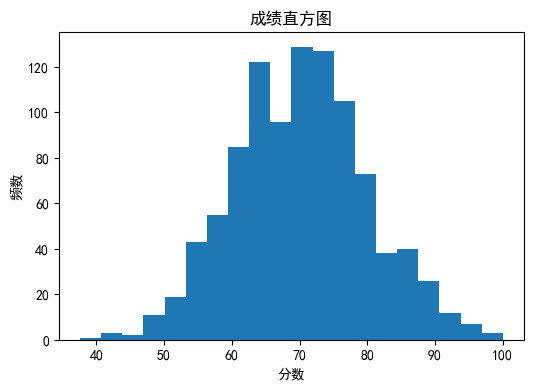

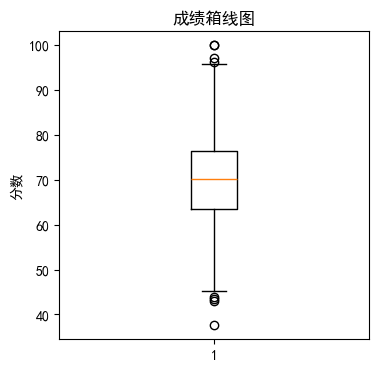

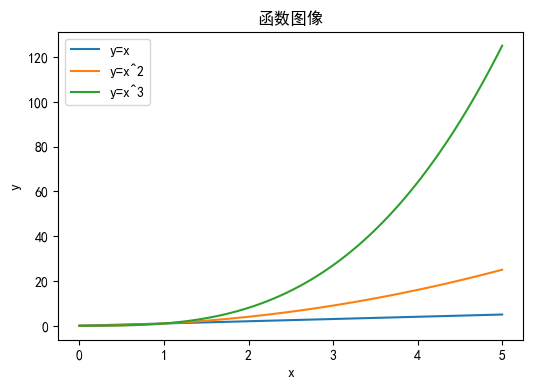

In [13]:
#5 matplotlib绘图
import matplotlib.pyplot as plt
# Windows用黑体SimHei，解决中文方框
plt.rcParams['font.sans-serif'] = ['SimHei']
# 解决负号也变成方框
plt.rcParams['axes.unicode_minus'] = False

# 关闭警告刷屏
import logging
mpl_log = logging.getLogger('matplotlib')
mpl_log.setLevel(logging.WARNING)

valid_score = scores[~numpy.isnan(scores_nan)]

plt.figure(figsize=(6,4))
plt.hist(valid_score,bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")
plt.show()

plt.figure(figsize=(4,4))
plt.boxplot(valid_score)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

# y=x; y=x²; y=x³ 0<=x<=5
x = numpy.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3
plt.figure(figsize=(6,4))
plt.plot(x,y1,label="y=x")
plt.plot(x,y2,label="y=x^2")
plt.plot(x,y3,label="y=x^3")
plt.legend()
plt.title("函数图像")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

实验4：实验4：pandas Series、DataFrame与内存中的CSV读写

In [14]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pandas.DataFrame(records)
df = df.set_index("Name") #行索引设置为姓名

#新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("df信息")
print("行索引：",df.index.tolist())
print("列名：",df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n统计描述：")
print(df.describe())

df信息
行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

统计描述：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [15]:
#2 loc iloc读取Carol，筛选平均分>=80
print("\nCarol记录 loc/iloc")
print(df.loc["Carol"])
#Carol是第2号下标(0开始)
print(df.iloc[2])

high_avg = df[df["Average"] >=80]
print("\n平均分>=80学生：")
print(high_avg)


Carol记录 loc/iloc
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分>=80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [16]:
#3 axis0列均值 axis1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n各科列均值(axis=0):")
print(col_mean)
print("\n每个学生行均值(axis=1):")
print(row_mean)


各科列均值(axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [17]:
#4 apply求最高分；agg；rank排名
df["max_score"] = df[["Math","English","Python"]].apply(max,axis=1)
agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
df["math_rank"] = df["Math"].rank(ascending=False)
print("\napply最高分：")
print(df[["max_score"]])
print("\nagg min mean max：")
print(agg_res)
print("\n数学成绩排名：")
print(df[["Math","math_rank"]])


apply最高分：
       max_score
Name            
Alice         95
Bob           80
Carol         91
David         73
Eva           92
Frank         84

agg min mean max：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学成绩排名：
       Math  math_rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [18]:
#5 groupby分组统计 + transform
group_stat = df.groupby("Group")[["Math","English","Python"]].agg(["count","mean"])
print("\n分组统计(人数、三科平均分)")
print(group_stat)

df["group_python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加本组Python平均分列：")
print(df[["Group","Python","group_python_mean"]])


分组统计(人数、三科平均分)
       Math            English            Python           
      count       mean   count       mean  count       mean
Group                                                      
A         3  79.666667       3  83.333333      3  87.000000
B         3  80.000000       3  78.333333      3  80.333333

增加本组Python平均分列：
      Group  Python  group_python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [19]:
#6 filter保留组内Python平均分>=80
group_filter = df.groupby("Group").filter(lambda g: g["Python"].mean()>=80)
print("\nfilter筛选Python组均分>=80的学生：")
print(group_filter)


filter筛选Python组均分>=80的学生：
      Group  Math  English  Python  Total    Average  max_score  math_rank  \
Name                                                                         
Alice     A    88       90      95    273  91.000000         95        2.0   
Bob       A    72       68      80    220  73.333333         80        5.0   
Carol     B    91       85      89    265  88.333333         91        1.0   
David     B    65       73      70    208  69.333333         73        6.0   
Eva       A    79       92      86    257  85.666667         92        4.0   
Frank     B    84       77      82    243  81.000000         84        3.0   

       group_python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [20]:
#7协方差、相关系数
score_cols = ["Math","English","Python"]
cov_mat = df[score_cols].cov()
corr_mat = df[score_cols].corr()
print("\n协方差矩阵：")
print(cov_mat)
print("\n皮尔逊相关系数矩阵：")
print(corr_mat)


协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


协方差：符号代表变量变化方向；正代表同增同减，负代表反向变化。
相关系数取值 [-1,1]；绝对值越接近 1 线性相关性越强；接近 0 代表线性无关。